In [1]:
import glob
import os
import pandas as pd
import kagglehub
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage,dendrogram
from sklearn.preprocessing import LabelEncoder
from sklearn.cluster import KMeans,AgglomerativeClustering
from sklearn.metrics import silhouette_score

/Users/siyasinnarkar/miniconda3/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
path = kagglehub.dataset_download("shwetabh123/mall-customers")
print(glob.glob(path+"/*"))
df=pd.read_csv(os.path.join(path,"Mall_Customers.csv"))

['/Users/siyasinnarkar/.cache/kagglehub/datasets/shwetabh123/mall-customers/versions/1/Mall_Customers.csv']


In [4]:
df['Genre']=LabelEncoder().fit_transform(df['Genre'])
df=df.drop('CustomerID',axis=1)
x=df[['Annual Income (k$)', 'Spending Score (1-100)']]

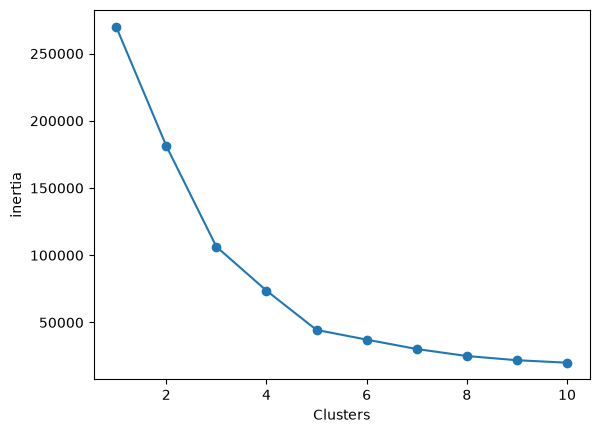

In [5]:
inertia=[]
for k in range(1,11):
    inertia.append(KMeans(n_clusters=k,random_state=42,n_init=10).fit(x).inertia_)
plt.plot(range(1,11),inertia,marker='o')
plt.xlabel("Clusters")
plt.ylabel("inertia")
plt.show()

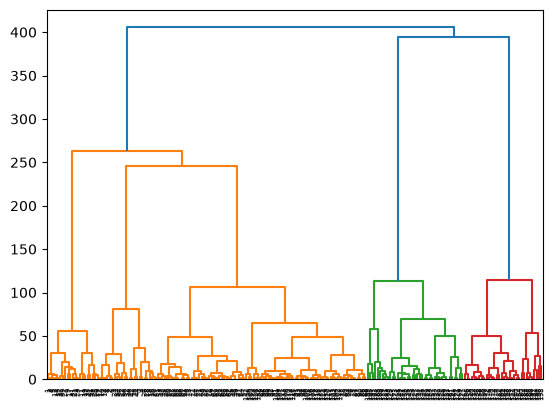

In [6]:
dendrogram(linkage(x,method='ward'))
plt.show()

In [8]:
km = KMeans(n_clusters=5, random_state=42, n_init=10)
df['KMeans'] = km.fit_predict(x)

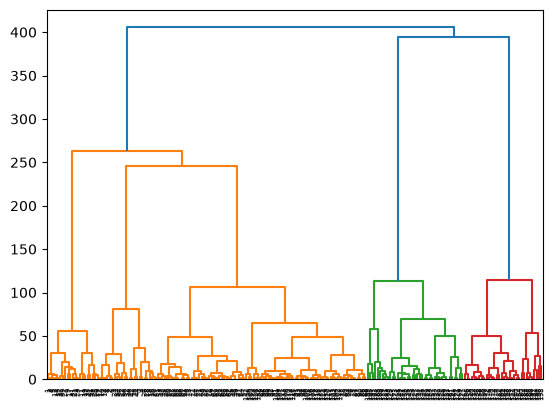

In [9]:
dendrogram(linkage(x, method='ward'))
plt.show()

In [10]:
hc = AgglomerativeClustering(n_clusters=5, linkage='ward')
df['Hierarchical'] = hc.fit_predict(x)

In [12]:
print("K-Means silhouette     :", silhouette_score(x, df['KMeans']))
print("Hierarchical silhouette:", silhouette_score(x, df['Hierarchical']))

K-Means silhouette     : 0.553931997444648
Hierarchical silhouette: 0.5529945955148897


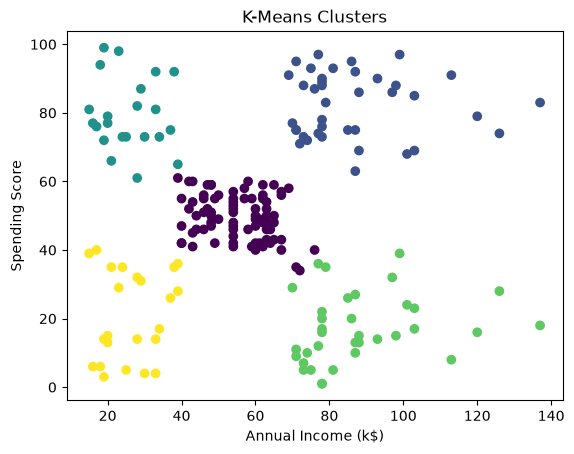

In [14]:
plt.scatter(x.iloc[:, 0], x.iloc[:, 1], c=df['KMeans'], cmap='viridis')
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score")
plt.title("K-Means Clusters")
plt.show()

In [15]:
print(df.groupby('KMeans')[['Annual Income (k$)', 'Spending Score (1-100)']].mean())

        Annual Income (k$)  Spending Score (1-100)
KMeans                                            
0                55.296296               49.518519
1                86.538462               82.128205
2                25.727273               79.363636
3                88.200000               17.114286
4                26.304348               20.913043
